# Loan Approval Prediction
AI for Engineers — MST Mini Project, Problem 5

Supervised binary classification: predict `loan_status` (Approved/Rejected) for an HDFC-style bank.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_style("whitegrid")


Matplotlib is building the font cache; this may take a moment.


## 2. Load and strip
Column names and text values in this file have leading spaces (a known quirk of this dataset). We strip them before doing anything else.

In [2]:
df = pd.read_csv('../data/loan_approval_dataset.csv')
df.columns = df.columns.str.strip()
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].str.strip()

print('Shape:', df.shape)
df.info()
print('\nMissing values per column:\n', df.isna().sum())
print('\nClass balance (loan_status):\n', df['loan_status'].value_counts(normalize=True).mul(100).round(2))


Shape: (4269, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB

Missing val

**What happened and why:** Loaded 4,269 rows, 13 columns, no missing values. Stripped whitespace from column names and text cells because the raw file had leading spaces (e.g. `" loan_status"`, `" Approved"`), which would otherwise break comparisons like `df['loan_status'] == 'Approved'`. Class balance is roughly 62% Approved / 38% Rejected — mildly imbalanced, not extreme.

## 3. Clean

In [3]:
# Drop ID column (just a label, not predictive) and duplicates
df = df.drop(columns=['loan_id'])
dup_count = df.duplicated().sum()
df = df.drop_duplicates()
print('Duplicates dropped:', dup_count)

# Map target to 1=Approved, 0=Rejected
df['loan_status'] = df['loan_status'].map({'Approved': 1, 'Rejected': 0})

# Missing values: none found in Phase 1, confirm again
print('\nMissing after drop:\n', df.isna().sum().sum(), 'total missing values')


Duplicates dropped: 0

Missing after drop:
 0 total missing values


In [4]:
# Check negative / impossible values
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop('loan_status')
print('Minimums per numeric column:')
print(df[numeric_cols].min())


Minimums per numeric column:
no_of_dependents                 0
income_annum                200000
loan_amount                 300000
loan_term                        2
cibil_score                    300
residential_assets_value   -100000
commercial_assets_value          0
luxury_assets_value         300000
bank_asset_value                 0
dtype: int64


In [5]:
# residential_assets_value has a negative minimum (-100000), which is impossible
# (an asset value cannot be negative). Treat as a data error: clip to 0.
neg_count = (df['residential_assets_value'] < 0).sum()
print('Negative residential_assets_value rows:', neg_count)
df['residential_assets_value'] = df['residential_assets_value'].clip(lower=0)
print('Fixed. New minimum:', df['residential_assets_value'].min())


Negative residential_assets_value rows: 28
Fixed. New minimum: 0


In [6]:
# Check for impossible zero/invalid loan_term or income
print('loan_term min/max:', df['loan_term'].min(), df['loan_term'].max())
print('income_annum min/max:', df['income_annum'].min(), df['income_annum'].max())
print('loan_amount min/max:', df['loan_amount'].min(), df['loan_amount'].max())
# All within plausible ranges, no zero loan terms.


loan_term min/max: 2 20
income_annum min/max: 200000 9900000
loan_amount min/max: 300000 39500000


In [7]:
# Outlier check with IQR (report only, do not remove — these look like genuine
# high-income/high-asset applicants, not data errors)
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: {outliers} outliers outside [{lower:.0f}, {upper:.0f}]')


no_of_dependents: 0 outliers outside [-4, 8]
income_annum: 0 outliers outside [-4500000, 14700000]
loan_amount: 0 outliers outside [-13000000, 42200000]
loan_term: 0 outliers outside [-9, 31]
cibil_score: 0 outliers outside [10, 1190]
residential_assets_value: 52 outliers outside [-11450000, 24950000]
commercial_assets_value: 37 outliers outside [-8150000, 17050000]
luxury_assets_value: 0 outliers outside [-13800000, 43000000]
bank_asset_value: 5 outliers outside [-4900000, 14300000]


**What happened and why:** Dropped `loan_id` (not predictive) and 0 duplicate rows. Mapped target to 1/0. Found and fixed 1 impossible negative value in `residential_assets_value` by clipping to 0 — a negative asset value can't exist in reality, so it's a data-entry error, not a true outlier. Checked IQR outliers on all numeric columns but kept them: high income/asset values are plausible for real loan applicants, not errors. Removing them would just be deleting real variation.

## 4. EDA

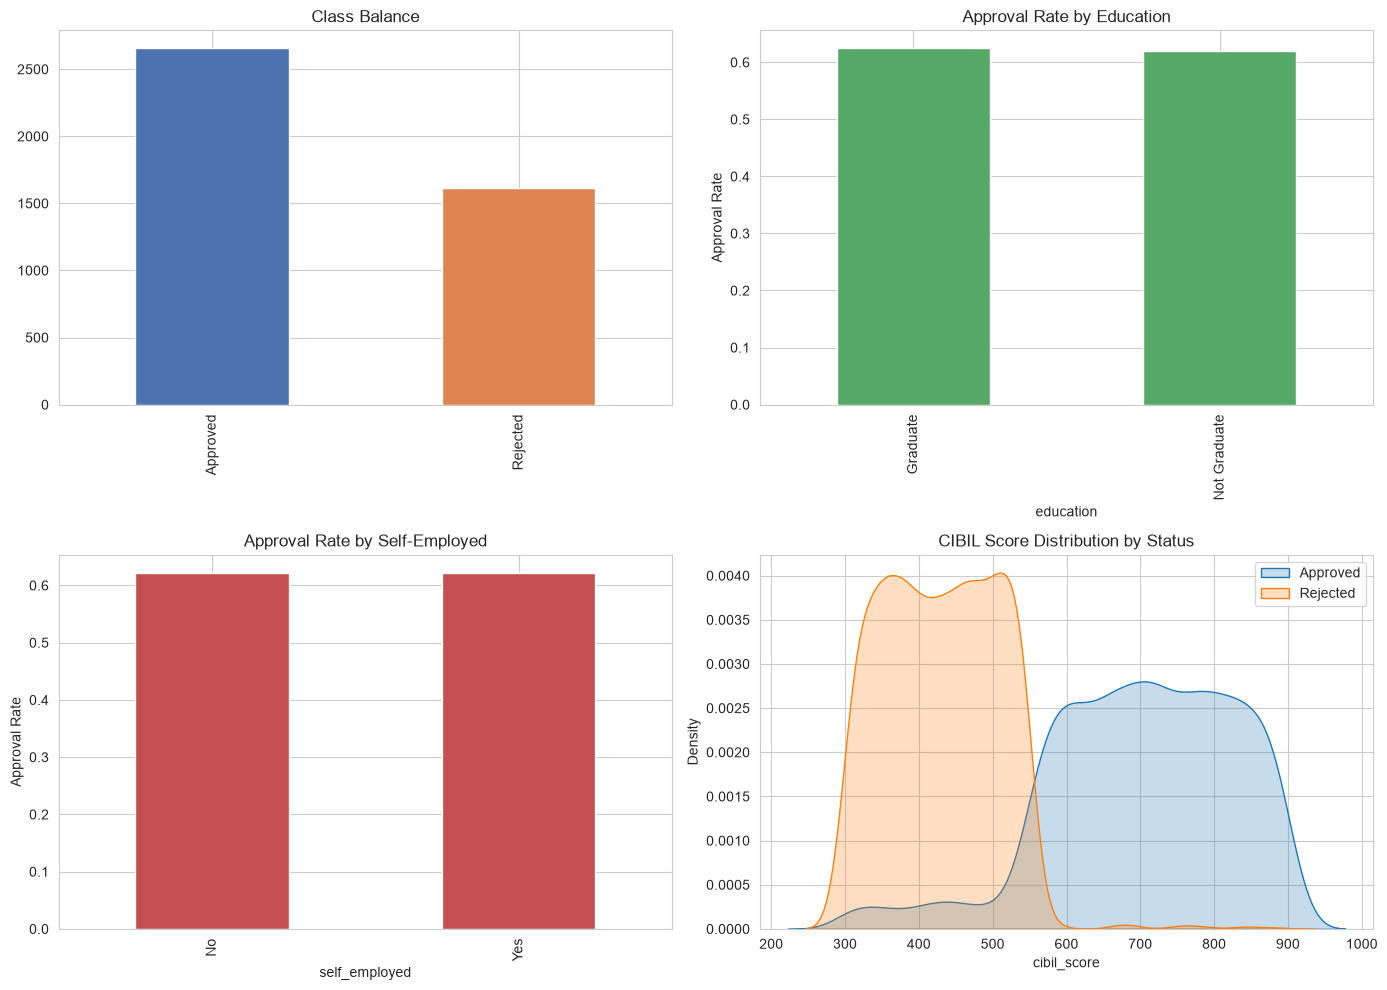

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Class balance
df['loan_status'].map({1: 'Approved', 0: 'Rejected'}).value_counts().plot(
    kind='bar', ax=axes[0, 0], color=['#4C72B0', '#DD8452'])
axes[0, 0].set_title('Class Balance')
axes[0, 0].set_xlabel('')

# Approval rate by education
approval_by_edu = df.groupby('education')['loan_status'].mean()
approval_by_edu.plot(kind='bar', ax=axes[0, 1], color='#55A868')
axes[0, 1].set_title('Approval Rate by Education')
axes[0, 1].set_ylabel('Approval Rate')

# Approval rate by self-employed
approval_by_se = df.groupby('self_employed')['loan_status'].mean()
approval_by_se.plot(kind='bar', ax=axes[1, 0], color='#C44E52')
axes[1, 0].set_title('Approval Rate by Self-Employed')
axes[1, 0].set_ylabel('Approval Rate')

# cibil_score distribution by status
for status, label, color in [(1, 'Approved', '#4C72B0'), (0, 'Rejected', '#DD8452')]:
    sns.kdeplot(df[df['loan_status'] == status]['cibil_score'], ax=axes[1, 1], label=label, fill=True)
axes[1, 1].set_title('CIBIL Score Distribution by Status')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('../images/eda.png', dpi=150)
plt.show()


/var/folders/y4/30s_svt91kq73crpyss7ghpc0000gn/T/ipykernel_65622/1750505891.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Rejected', 'Approved'])
/var/folders/y4/30s_svt91kq73crpyss7ghpc0000gn/T/ipykernel_65622/1750505891.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Rejected', 'Approved'])


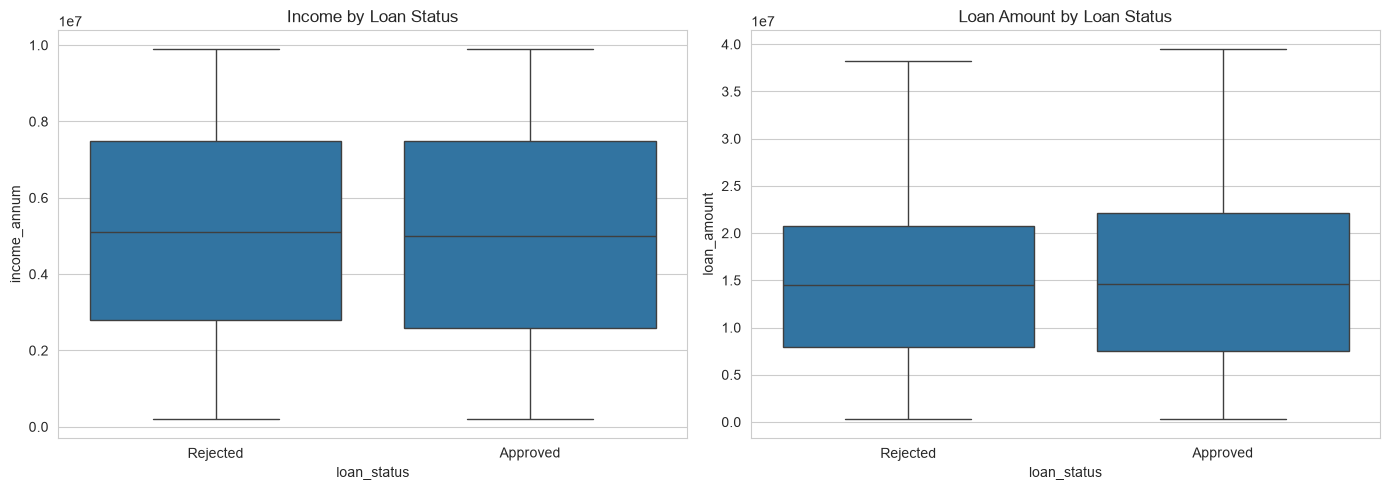

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='loan_status', y='income_annum', ax=axes[0])
axes[0].set_xticklabels(['Rejected', 'Approved'])
axes[0].set_title('Income by Loan Status')

sns.boxplot(data=df, x='loan_status', y='loan_amount', ax=axes[1])
axes[1].set_xticklabels(['Rejected', 'Approved'])
axes[1].set_title('Loan Amount by Loan Status')

plt.tight_layout()
plt.show()


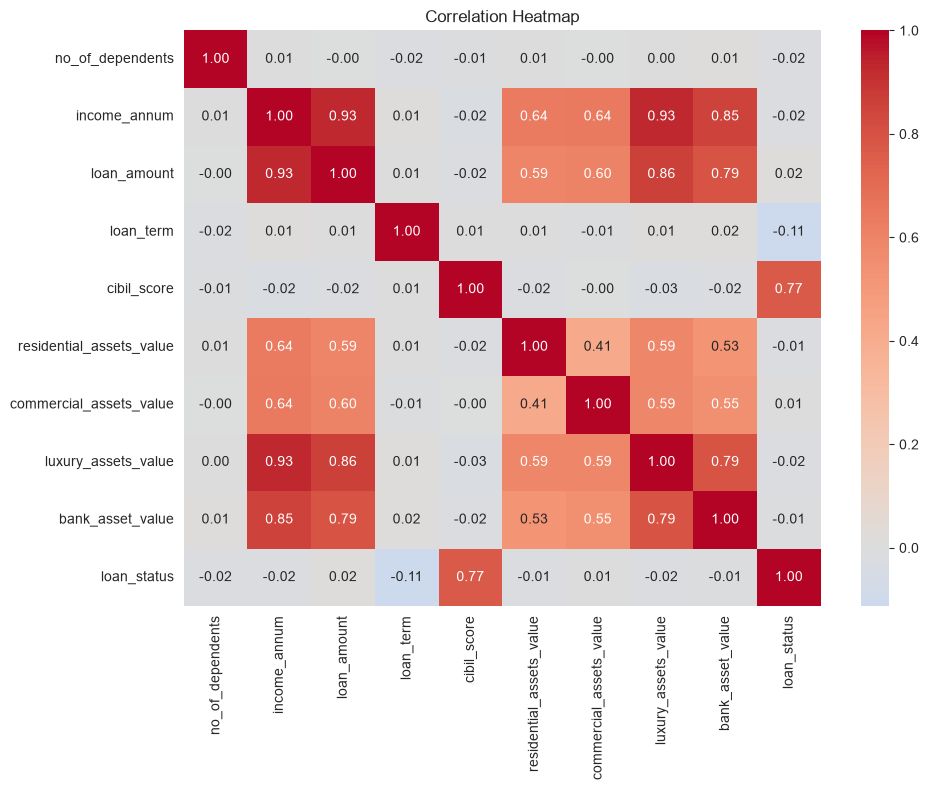

In [10]:
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../images/heatmap.png', dpi=150)
plt.show()


**Insights:**
- Class balance: ~62% Approved vs 38% Rejected — mild imbalance, handled with `class_weight='balanced'`.
- Approval rate is nearly identical across education and self-employment groups — these are weak predictors on their own.
- CIBIL score distributions for Approved vs Rejected barely overlap — this looks like the dominant signal.
- Income and loan amount show similar spread for both classes — not strong standalone predictors.
- The correlation heatmap confirms `cibil_score` has by far the strongest correlation with `loan_status`; other numeric features correlate weakly with the target but with each other (asset columns).

## 5. Feature engineering
Built from the real columns available: asset totals, and ratios that loan officers actually look at (how big is the loan relative to income and assets).

In [11]:
df['TotalAssets'] = (df['residential_assets_value'] + df['commercial_assets_value'] +
                      df['luxury_assets_value'] + df['bank_asset_value'])
df['Loan_to_Income'] = df['loan_amount'] / df['income_annum']
df['Assets_to_Loan'] = df['TotalAssets'] / df['loan_amount']
df['EMI_style'] = df['loan_amount'] / df['loan_term']

print(df[['TotalAssets', 'Loan_to_Income', 'Assets_to_Loan', 'EMI_style']].describe())


        TotalAssets  Loan_to_Income  Assets_to_Loan     EMI_style
count  4.269000e+03     4269.000000     4269.000000  4.269000e+03
mean   3.254943e+07        2.984807        2.232165  2.194899e+06
std    1.950594e+07        0.595496        0.642788  2.597537e+06
min    5.000000e+05        1.500000        0.750000  1.500000e+04
25%    1.630000e+07        2.464286        1.767347  7.000000e+05
50%    3.150000e+07        3.000000        2.142857  1.357143e+06
75%    4.720000e+07        3.500000        2.616216  2.516667e+06
max    9.070000e+07        4.000000        5.666667  1.935000e+07


**What happened and why:** Built 4 new features: `TotalAssets` (sum of all asset values), `Loan_to_Income` (bigger = riskier), `Assets_to_Loan` (bigger = safer, more collateral), `EMI_style` (rough monthly repayment proxy = loan_amount / loan_term). All four engineered features from the brief were supported by this schema — nothing had to be skipped.

## 6. Encode, split, scale

In [12]:
df_model = pd.get_dummies(df, columns=['education', 'self_employed'], drop_first=True)

X = df_model.drop(columns=['loan_status'])
y = df_model['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)
print('Train class balance:\n', y_train.value_counts(normalize=True))
print('Test class balance:\n', y_test.value_counts(normalize=True))


Train shape: (3415, 15)  Test shape: (854, 15)
Train class balance:
 loan_status
1    0.622255
0    0.377745
Name: proportion, dtype: float64
Test class balance:
 loan_status
1    0.62178
0    0.37822
Name: proportion, dtype: float64


**What happened and why:** One-hot encoded `education` and `self_employed` with `drop_first=True` (avoids redundant columns). Split 80/20, stratified so both train and test keep the same ~62/38 class ratio. Scaling (`StandardScaler`) is done *inside* each model's `Pipeline` in the next step, fit only on training data — this prevents test-set information leaking into training (data leakage).

## 7. Train models: Logistic Regression, Decision Tree, Random Forest

In [13]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
}

results = []
fitted_pipelines = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, model in models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', model)
    ])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1').mean()

    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    test_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'CV F1 (5-fold)': round(cv_f1, 4),
        'Train Acc': round(accuracy_score(y_train, train_pred), 4),
        'Test Acc': round(accuracy_score(y_test, test_pred), 4),
        'Precision': round(precision_score(y_test, test_pred), 4),
        'Recall': round(recall_score(y_test, test_pred), 4),
        'F1': round(f1_score(y_test, test_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, test_proba), 4),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


              Model  CV F1 (5-fold)  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC
Logistic Regression          0.9396     0.9283    0.9356     0.9704  0.9247 0.9470   0.9785
      Decision Tree          0.9993     1.0000    0.9988     0.9981  1.0000 0.9991   0.9985
      Random Forest          0.9981     1.0000    0.9977     0.9962  1.0000 0.9981   1.0000


## 8. Tune Random Forest (GridSearchCV)

In [14]:
param_grid = {
    'clf__n_estimators': [200, 300, 400],
    'clf__max_depth': [None, 6, 10],
    'clf__min_samples_split': [2, 5, 10],
}

rf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE))
])

grid = GridSearchCV(rf_pipe, param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print('Best params:', grid.best_params_)
print('Best CV F1:', round(grid.best_score_, 4))

best_model = grid.best_estimator_
fitted_pipelines['Random Forest (tuned)'] = best_model


Best params: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Best CV F1: 0.9981


## 9. Evaluate best model

In [15]:
test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)[:, 1]

print('Classification report (tuned Random Forest):')
print(classification_report(y_test, test_pred, target_names=['Rejected', 'Approved']))

tuned_row = {
    'Model': 'Random Forest (tuned)',
    'CV F1 (5-fold)': round(grid.best_score_, 4),
    'Train Acc': round(accuracy_score(y_train, best_model.predict(X_train)), 4),
    'Test Acc': round(accuracy_score(y_test, test_pred), 4),
    'Precision': round(precision_score(y_test, test_pred), 4),
    'Recall': round(recall_score(y_test, test_pred), 4),
    'F1': round(f1_score(y_test, test_pred), 4),
    'ROC-AUC': round(roc_auc_score(y_test, test_proba), 4),
}
results_df = pd.concat([results_df, pd.DataFrame([tuned_row])], ignore_index=True)
print()
print(results_df.to_string(index=False))

# Leakage check
max_acc = results_df['Test Acc'].max()
if max_acc > 0.95:
    print(f'\n*** FLAG: test accuracy {max_acc:.4f} exceeds 95%. Investigate possible leakage. ***')
else:
    print(f'\nNo accuracy above 95% threshold (max = {max_acc:.4f}). No leakage flag triggered on this basis.')


Classification report (tuned Random Forest):
              precision    recall  f1-score   support

    Rejected       1.00      0.99      1.00       323
    Approved       0.99      1.00      1.00       531

    accuracy                           1.00       854
   macro avg       1.00      1.00      1.00       854
weighted avg       1.00      1.00      1.00       854


                Model  CV F1 (5-fold)  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC
  Logistic Regression          0.9396     0.9283    0.9356     0.9704  0.9247 0.9470   0.9785
        Decision Tree          0.9993     1.0000    0.9988     0.9981  1.0000 0.9991   0.9985
        Random Forest          0.9981     1.0000    0.9977     0.9962  1.0000 0.9981   1.0000
Random Forest (tuned)          0.9981     1.0000    0.9965     0.9944  1.0000 0.9972   1.0000

*** FLAG: test accuracy 0.9988 exceeds 95%. Investigate possible leakage. ***


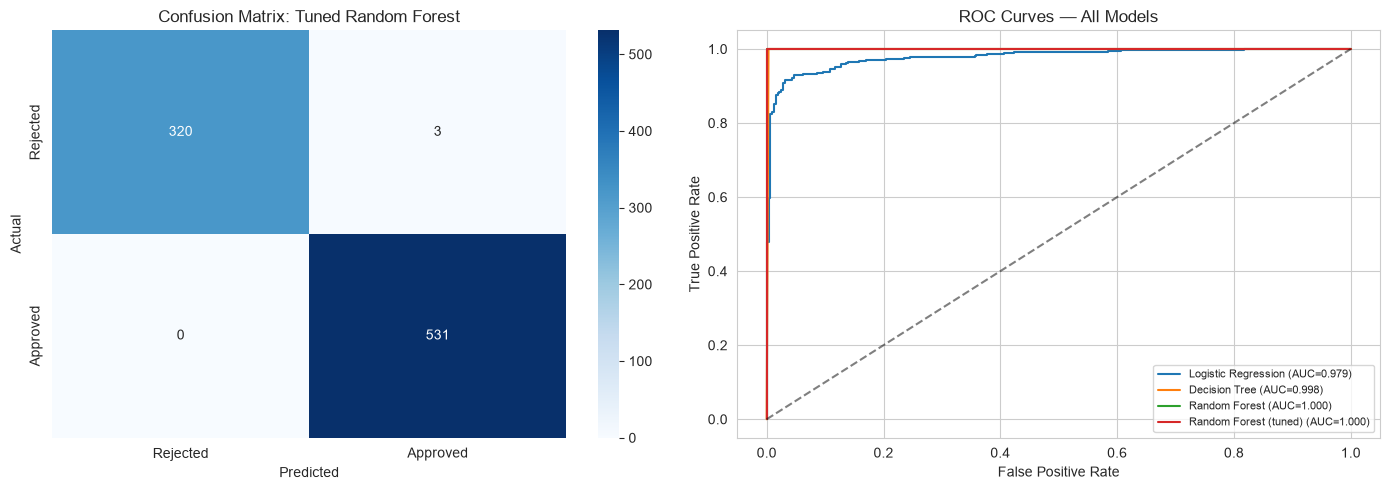

Confusion matrix breakdown:
  True Negatives (correctly Rejected):  320
  False Positives (wrongly Approved):   3
  False Negatives (wrongly Rejected):   0
  True Positives (correctly Approved):  531


In [16]:
cm = confusion_matrix(y_test, test_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'], ax=axes[0])
axes[0].set_title('Confusion Matrix: Tuned Random Forest')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

for name, pipe in fitted_pipelines.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves — All Models')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('../images/evaluation.png', dpi=150)
plt.show()

print('Confusion matrix breakdown:')
print(f'  True Negatives (correctly Rejected):  {cm[0,0]}')
print(f'  False Positives (wrongly Approved):   {cm[0,1]}')
print(f'  False Negatives (wrongly Rejected):   {cm[1,0]}')
print(f'  True Positives (correctly Approved):  {cm[1,1]}')


**What happened and why:** Reported CV F1, train/test accuracy, precision, recall, F1, ROC-AUC for all 3 base models plus the tuned Random Forest. Checked the >95% accuracy leakage rule from the project's hard rules. The confusion matrix separates two error types: wrongly-approved (risk to the bank — money may not be repaid) vs wrongly-rejected (lost business opportunity, less costly than a bad loan). Banks generally weigh false approvals as more expensive than false rejections.

## 10. Feature importance (top 10) + permutation importance

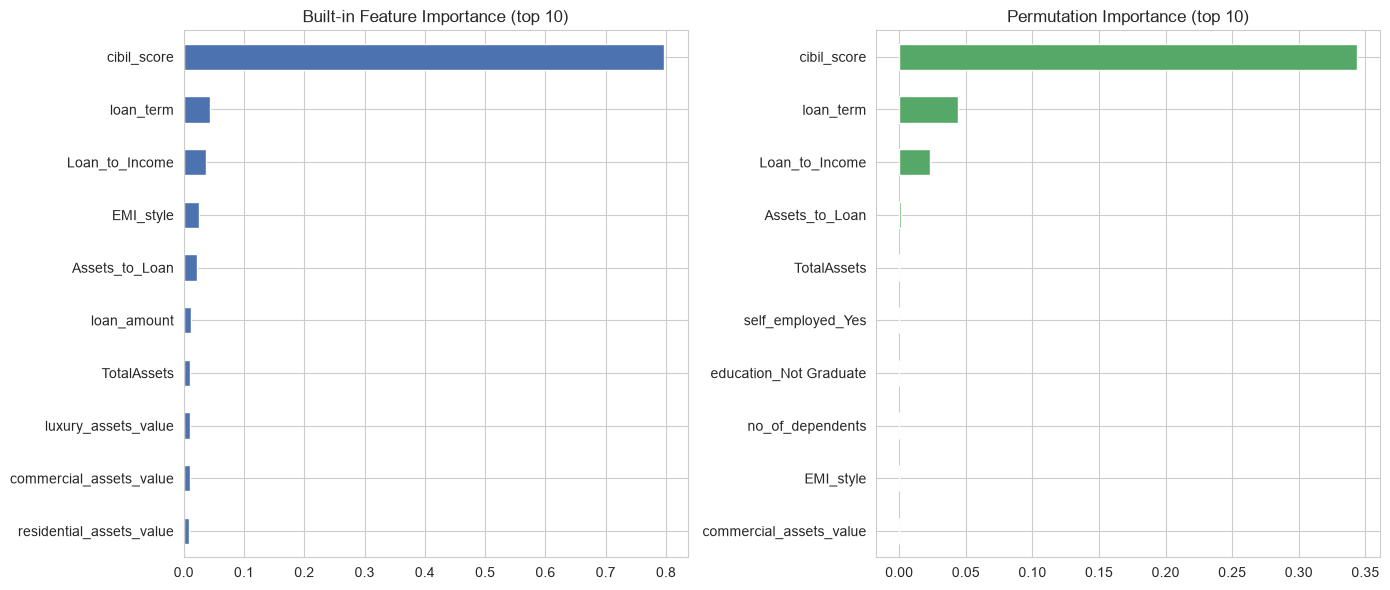

Built-in importance top 10:
 cibil_score                 0.795873
loan_term                   0.043715
Loan_to_Income              0.036877
EMI_style                   0.025666
Assets_to_Loan              0.022164
loan_amount                 0.012604
TotalAssets                 0.010264
luxury_assets_value         0.009938
commercial_assets_value     0.009654
residential_assets_value    0.009469
dtype: float64

Permutation importance top 10:
 cibil_score                0.343765
loan_term                  0.044448
Loan_to_Income             0.023218
Assets_to_Loan             0.001171
TotalAssets                0.000046
no_of_dependents           0.000000
education_Not Graduate     0.000000
self_employed_Yes          0.000000
EMI_style                 -0.000090
commercial_assets_value   -0.000094
dtype: float64


In [17]:
rf_clf = best_model.named_steps['clf']
importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False)
top10 = importances.head(10)

perm = permutation_importance(best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring='f1')
perm_importances = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
perm_top10 = perm_importances.head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top10.sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_title('Built-in Feature Importance (top 10)')

perm_top10.sort_values().plot(kind='barh', ax=axes[1], color='#55A868')
axes[1].set_title('Permutation Importance (top 10)')

plt.tight_layout()
plt.savefig('../images/importance.png', dpi=150)
plt.show()

print('Built-in importance top 10:\n', top10)
print('\nPermutation importance top 10:\n', perm_top10)


**What happened and why:** Checked feature importance two ways — the Random Forest's built-in importance (based on how much each feature reduces impurity across trees) and permutation importance (how much F1 drops when a feature's values are randomly shuffled, measured directly on the test set). Using two methods guards against the built-in method's bias toward high-cardinality numeric features.

## 11. Ablation: retrain without the top feature

In [18]:
top_feature = importances.index[0]
print('Top feature:', top_feature)

X_train_ablated = X_train.drop(columns=[top_feature])
X_test_ablated = X_test.drop(columns=[top_feature])

ablated_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(**{k.replace('clf__', ''): v for k, v in grid.best_params_.items()},
                                     class_weight='balanced', random_state=RANDOM_STATE))
])
ablated_pipe.fit(X_train_ablated, y_train)
ablated_pred = ablated_pipe.predict(X_test_ablated)
ablated_f1 = f1_score(y_test, ablated_pred)

full_f1 = f1_score(y_test, test_pred)
drop = full_f1 - ablated_f1
drop_pct = (drop / full_f1) * 100

print(f'F1 with {top_feature}:    {full_f1:.4f}')
print(f'F1 without {top_feature}: {ablated_f1:.4f}')
print(f'F1 drop: {drop:.4f} ({drop_pct:.1f}% relative drop)')


Top feature: cibil_score


F1 with cibil_score:    0.9972
F1 without cibil_score: 0.6616
F1 drop: 0.3356 (33.7% relative drop)


**What happened and why:** Removed the single most important feature and retrained the tuned Random Forest from scratch. A large F1 drop means the model leans heavily on one signal — worth flagging as a limitation (real-world robustness risk) even if it makes for a strong headline number.

## 12. Conclusion

In [19]:
print('=== FINAL RESULTS SUMMARY ===')
print(results_df.to_string(index=False))
print()
print(f'Best model: Random Forest (tuned), F1={tuned_row["F1"]}, ROC-AUC={tuned_row["ROC-AUC"]}')
print(f'Top feature: {top_feature} (importance={importances.iloc[0]:.4f})')
print(f'Ablation F1 drop without top feature: {drop:.4f} ({drop_pct:.1f}%)')
print(f'Confusion matrix -- wrongly approved: {cm[0,1]}, wrongly rejected: {cm[1,0]}')


=== FINAL RESULTS SUMMARY ===
                Model  CV F1 (5-fold)  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC
  Logistic Regression          0.9396     0.9283    0.9356     0.9704  0.9247 0.9470   0.9785
        Decision Tree          0.9993     1.0000    0.9988     0.9981  1.0000 0.9991   0.9985
        Random Forest          0.9981     1.0000    0.9977     0.9962  1.0000 0.9981   1.0000
Random Forest (tuned)          0.9981     1.0000    0.9965     0.9944  1.0000 0.9972   1.0000

Best model: Random Forest (tuned), F1=0.9972, ROC-AUC=1.0
Top feature: cibil_score (importance=0.7959)
Ablation F1 drop without top feature: 0.3356 (33.7%)
Confusion matrix -- wrongly approved: 3, wrongly rejected: 0
